# What does a new cell cost?

This experiment asks what process sets births per boundary read. See [the protocol](README.md) and [the append-only log](NOTEBOOK.md). Calibrated recording exposed an unsupported rich lookup; a finite colour-memory closure subsequently failed both registered cost and return-budget tests. The main cohort remains unrun.

The immediate birth is fixed by the current turn and visited-neighbour mask. The unknown is their distribution. Births are not assumed independent regeneration points, and a pooled cross-rule transition matrix must respect target-rule-compatible successor states.

## Provenance and design
The following cell reads only committed design files under this experiment's results directory, verifies their hashes and checks assignment invariants. Counts below describe a planned cohort, not measured ants. It runs from the repository root or any descendant directory.

In [1]:
import csv, hashlib, json, subprocess
from collections import Counter, defaultdict
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Cargo.toml').exists() and (p / 'experiments').is_dir())
EXP = ROOT / 'experiments/active/2026-10-c-law-renewal'
inputs = [EXP / 'results/design/families.csv', EXP / 'results/design/provenance.json']
for p in inputs:
    subprocess.run(['git', 'ls-files', '--error-unmatch', str(p.relative_to(ROOT))], cwd=ROOT, check=True, capture_output=True)
    subprocess.run(['git', '-c', 'core.filemode=false', 'diff', '--exit-code', 'HEAD', '--', str(p.relative_to(ROOT))], cwd=ROOT, check=True, capture_output=True)
    print(hashlib.sha256(p.read_bytes()).hexdigest(), p.relative_to(ROOT))
provenance = json.loads(inputs[1].read_text())
assert hashlib.sha256(inputs[0].read_bytes()).hexdigest() == provenance['manifest_sha256']
print('Source revision:', provenance['base_revision'])
print('Notebook revision:', subprocess.check_output(['git', 'rev-parse', 'HEAD'], cwd=ROOT, text=True).strip())
print('Sampling seed:', provenance['sampling_seed'])
rows = list(csv.DictReader(inputs[0].open()))
families = defaultdict(list)
for row in rows:
    families[row['family']].append(row)
def necklace(rule):
    mirror = rule.translate(str.maketrans('RL', 'LR'))
    return min(r[i:] + r[:i] for r in (rule, mirror) for i in range(len(r)))
assert len({necklace(r['rule']) for r in rows}) == len(rows)
for family in families.values():
    assert len(family) == 3 and len({r['split'] for r in family}) == 1
    assert {r['arm'] for r in family} == {'base', 'early_swap', 'late_swap'}
    assert len({r['rule'].count('R') for r in family}) == 1
    for r in family:
        assert len(r['rule']) - len(r['rule'].lstrip('R')) == int(r['lead'])
print('Planned families by split:', dict(sorted(Counter(f[0]['split'] for f in families.values()).items())))
print('Planned rules:', len(rows))
print('This cell audits planned assignments only; pilot outcomes are audited below.')

bc37ff7e19aa4102dbbec69d17d39cb13986ea73f9225343263cad9eb1b946c8 experiments/2026-10-20-c-law-renewal/results/design/families.csv
46df2597f5e2fdab027d097513467be8f4c1913fd04667d219a9b8f34370b28a experiments/2026-10-20-c-law-renewal/results/design/provenance.json
Source revision: adf66774570469da30b10ffc1ceab911670a9d09
Notebook revision: 94516e5c277ce026c3b5f5cea03545e2654338e1
Sampling seed: 2026102001
Planned families by split: {'pilot': 4, 'train': 32, 'validation': 16}
Planned rules: 156
This cell audits planned assignments only; pilot outcomes are audited below.


## Method and controls
The source recorder is compared event by event to a sparse independent path oracle, plus exact totals against the existing aggregate tracer. The solver is calibrated on known two-state reward chains and challenged by hidden history. Rotor and random-walk controls use eight seeds each. The excluded pilot uses four families, three arms and two interior seeds, with horizons 2^22..2^26. Commands, seeds, thresholds and binary hashes are in the README and result provenance.

No main transition model is fitted. Draft P1–P4 remain untested; G1's solver calibration does not calibrate an ant state/backoff model. The support repeat at k=26 is a registered feasibility diagnostic after the horizon failure, not a rescue of the gate.

## What remains unestablished
There is no validated local renewal model, no derived intercept or slope, and no new mechanism claim about kappa. The pilot gate failed; no families were replaced and no validation outcomes were opened. Unseen-state mass is only a feasibility check, not a measure of predictive accuracy. Coarsening can improve support while destroying relevant information.

Next decisions must address both sampling failures and target-rule-compatible transitions. A good total birth rate alone cannot show Markov closure; the hidden-history calibration supplies a counterexample.

## Pilot provenance and results
Only committed JSON/CSV summaries are read. Every input is checked for content changes and hashed; ignored event dumps are not notebook inputs. Uncertainty below is between seeds, not a fit standard error.


In [2]:
files = [EXP / 'results' / name for name in ['calibration.json', 'pilot_report.json', 'pilot_diagnostics.json', 'pilot_diagnostics.csv']]
if (EXP / 'results/support_report.json').exists():
    files.append(EXP / 'results/support_report.json')
for p in files:
    subprocess.run(['git', 'ls-files', '--error-unmatch', str(p.relative_to(ROOT))], cwd=ROOT, check=True, capture_output=True)
    subprocess.run(['git', '-c', 'core.filemode=false', 'diff', '--exit-code', 'HEAD', '--', str(p.relative_to(ROOT))], cwd=ROOT, check=True, capture_output=True)
    print(hashlib.sha256(p.read_bytes()).hexdigest(), p.relative_to(ROOT))
calibration, controls, diagnostic = [json.loads(p.read_text()) for p in files[:3]]
support = json.loads(files[4].read_text()) if len(files) == 5 else None
assert calibration['passed']
print('Synthetic reward solver: maximum |c error|', calibration['max_absolute_error'], 'signed bias', calibration['signed_bias'], 'between-seed sd', calibration['between_seed_sd'])
print('Hidden-history control: pooled c', calibration['negative_control']['pooled_c'], 'conditional contrast', calibration['negative_control']['contrast'])
for walker, result in controls['controls'].items():
    assert result['passed'] and result['n'] == 8
    print(walker, 'c mean', result['mean'], 'between-seed sd', result['between_seed_sd'], 'escapes', result['escapes'])
assert controls['thread_check']['identical']
assert controls['horizon']['selected_log2'] is None
print('Original pilot horizon verdict:', controls['horizon']['status'])
print('Usable k=26 runs:', diagnostic['k26_usable_runs'], '/', diagnostic['k26_n'])
for name, result in (support['models'] if support else {}).items():
    print(name, 'unseen read mass median', result['median_unseen_mass'], 'maximum', result['max_unseen_mass'], 'runs >5%', result['runs_over_5pct'])
if support is None:
    print('Excluded support diagnostic is pending; no support verdict yet.')
print('These outputs are calibration and feasibility evidence; P1-P4 are untested.')


223c59d49fb1c2e3033630f941e5c2fff86b120e4855cac4ae6ae7222e394786 experiments/2026-10-20-c-law-renewal/results/calibration.json
60c51af722ba71a690fbe7290697f3fb72e9e6e2644fac48a6c45554e5ec3a4e experiments/2026-10-20-c-law-renewal/results/pilot_report.json
0c79950115ec834669cd9ede9a8c73846278caa250951a85bbc97d0ae78aa0d3 experiments/2026-10-20-c-law-renewal/results/pilot_diagnostics.json


aff83d63c41f98a45d30ddff3f4b13817084f397c2d3c8f537e4d54b78c8a553 experiments/2026-10-20-c-law-renewal/results/pilot_diagnostics.csv
2ef41335ed667d842ef7a1252d7f7a0a0bef4f1974be1d7c8e94074a537b03c1 experiments/2026-10-20-c-law-renewal/results/support_report.json
Synthetic reward solver: maximum |c error| 0.0018502018274182408 signed bias 0.0002107888335104724 between-seed sd 0.000865310084626809
Hidden-history control: pooled c 0.499742 conditional contrast 0.8029957507452465
rotor c mean 0.4975039943500837 between-seed sd 0.00046687638082219373 escapes 0
rw c mean 0.44660243172590325 between-seed sd 0.008121941614407723 escapes 0
Original pilot horizon verdict: STOP_register_geometry_or_budget_revision
Usable k=26 runs: 2 / 24
S0 unseen read mass median 1.0 maximum 1.0 runs >5% 24
S1 unseen read mass median 1.0 maximum 1.0 runs >5% 24
S2 unseen read mass median 1.0 maximum 1.0 runs >5% 24
C0 unseen read mass median 0.008884325343085211 maximum 0.06893571487365215 runs >5% 4
C1 unseen r

## Interpretation and next discrimination
The controls validate recording and the narrow solver task. They do not validate a model of ant state frequencies. The original pilot failed to supply a common sampling window; its support diagnostic cannot retroactively make that gate pass. Full eight-turn states may encode family identity and lose transfer support. A smaller state still needs a generative transition rule consistent with the target rule and a test against hidden history.


## Finite colour memory: an exact-rule intervention
Keep the target rule's exact colour clock inside a moving Chebyshev-radius r patch. On a forgotten re-read sample a uniform phase; first reads retain the original phase. The model creates its own path and visited geometry, without target state frequencies. Compare full, r=0/1/2/4/8 and zero-reset r=4 on four excluded base rules and two seeds.

Before measuring, replace the proposed fixed-time window by 2048 warmup boundary reads followed by 8192 measurement reads, capped at 2^28 steps. At most 10240 births can occur before a complete stop, preventing band depletion. Report every cap. This prospectively amended pilot does not rescue the original failed horizon gate.

Exact deduction: a k-step returning quarter-turn path can stray at most k/4 cells in either coordinate. Forgetting at radius r requires return lag at least 4(r+1). Thus r=4 directly resets only >16-step phases. Independent eviction/path/window oracles and exhaustive 16-step turn-word checks precede data; full release tests pass. Calibration and finite-window bias appear below.


In [3]:
import numpy as np
memory_files = [EXP / 'results' / name for name in ['memory_report.json', 'memory_diagnostics.json', 'memory_v1/controls.json', 'memory_pilot.png']]
for p in memory_files:
    subprocess.run(['git', 'ls-files', '--error-unmatch', str(p.relative_to(ROOT))], cwd=ROOT, check=True, capture_output=True)
    subprocess.run(['git', '-c', 'core.filemode=false', 'diff', '--exit-code', 'HEAD', '--', str(p.relative_to(ROOT))], cwd=ROOT, check=True, capture_output=True)
    print(hashlib.sha256(p.read_bytes()).hexdigest(), p.relative_to(ROOT))
memory, memory_diagnostic, memory_controls = [json.loads(p.read_text()) for p in memory_files[:3]]
for walker, result in memory_controls['controls'].items():
    assert result['passed'] and result['n'] == 8
    print(walker, 'boundary-clock c', result['mean'], 'between-seed sd', result['between_seed_sd'], 'difference vs old fixed time', result['difference_from_parent_fixed_time_mean'])
for mode, result in memory['tests'].items():
    pairs = [r for r in memory['comparisons'] if r['mode']==mode and r['eligible']]
    errors = [float('inf') if r['error_infinite'] else r['abs_log_error'] for r in pairs]
    budgets = [float('inf') if r['budget_error_infinite'] else r['max_budget_error'] for r in pairs]
    assert len(pairs) == result['eligible_pairs']
    assert np.isclose(np.median(errors), result['median_abs_log_error'])
    assert np.isclose(max(errors), result['max_abs_log_error'])
    assert np.isclose(np.median(budgets), result['median_max_budget_error'])
    print(mode, 'n', len(pairs), 'median |ln c ratio|', np.median(errors), 'max', max(errors), 'median max budget error', np.median(budgets), 'M1', result['M1'], 'M2', result['M2'])
print('M3', memory['policy']['M3'], 'defined pairs', memory['policy']['eligible_defined_pairs'])
for row in memory_diagnostic['decomposition']:
    if row['lead']==4 and row['mode']=='uniform:4':
        print(row['rule'], row['seed'], 'signed cost change', row['delta_reads_per_birth'], 'first/lag4/short/long', row['signed_budget_delta_first_lag4_short_long'])
print('Max full-ant absolute ln event-clock/fixed-time c:', max(abs(r['ln_event_over_fixed']) for r in memory_diagnostic['clock_audit']))
print('Main P1-P4 untested. Four rules, two seeds each; no confidence interval or universal locality claim.')


313cee96d78355d2ada2320198eeedbaf2ddb82ef9d24291751bc84dbdbf7c4f experiments/2026-10-20-c-law-renewal/results/memory_report.json
7b742081ea5894b4fcfc6d57c80992090d194bc99af0c315584ebbc1cff18713 experiments/2026-10-20-c-law-renewal/results/memory_diagnostics.json


12692c5cfd5ff2a45848bab3a5684a4002b066c57660c1aa84949168e4245902 experiments/2026-10-20-c-law-renewal/results/memory_v1/controls.json
c5ee5b43bc1f42af437e3ebadb2b1b2c838843ef7d420adf7e54f3d296862830 experiments/2026-10-20-c-law-renewal/results/memory_pilot.png
rotor boundary-clock c 0.5007476806640625 between-seed sd 0.0031329445670095434 difference vs old fixed time 0.003243686313978811
rw boundary-clock c 0.462432861328125 between-seed sd 0.006131614311152842 difference vs old fixed time 0.01583042960222175
uniform:4 n 8 median |ln c ratio| 0.012053640265808484 max 0.29892578143930193 median max budget error 0.24866150578978552 M1 FAILED M2 FAILED
uniform:8 n 8 median |ln c ratio| 0.012622660828981086 max 0.27618482008612333 median max budget error 0.20088074993888094 M1 FAILED M2 FAILED
M3 UNINFORMATIVE defined pairs 2
RRRRLLRRLLLLRR 2026102021 signed cost change -0.9532008227204058 first/lag4/short/long [-0.0016575492669566039, 0.5133090279438044, 0.16954745468829002, -1.6343997560

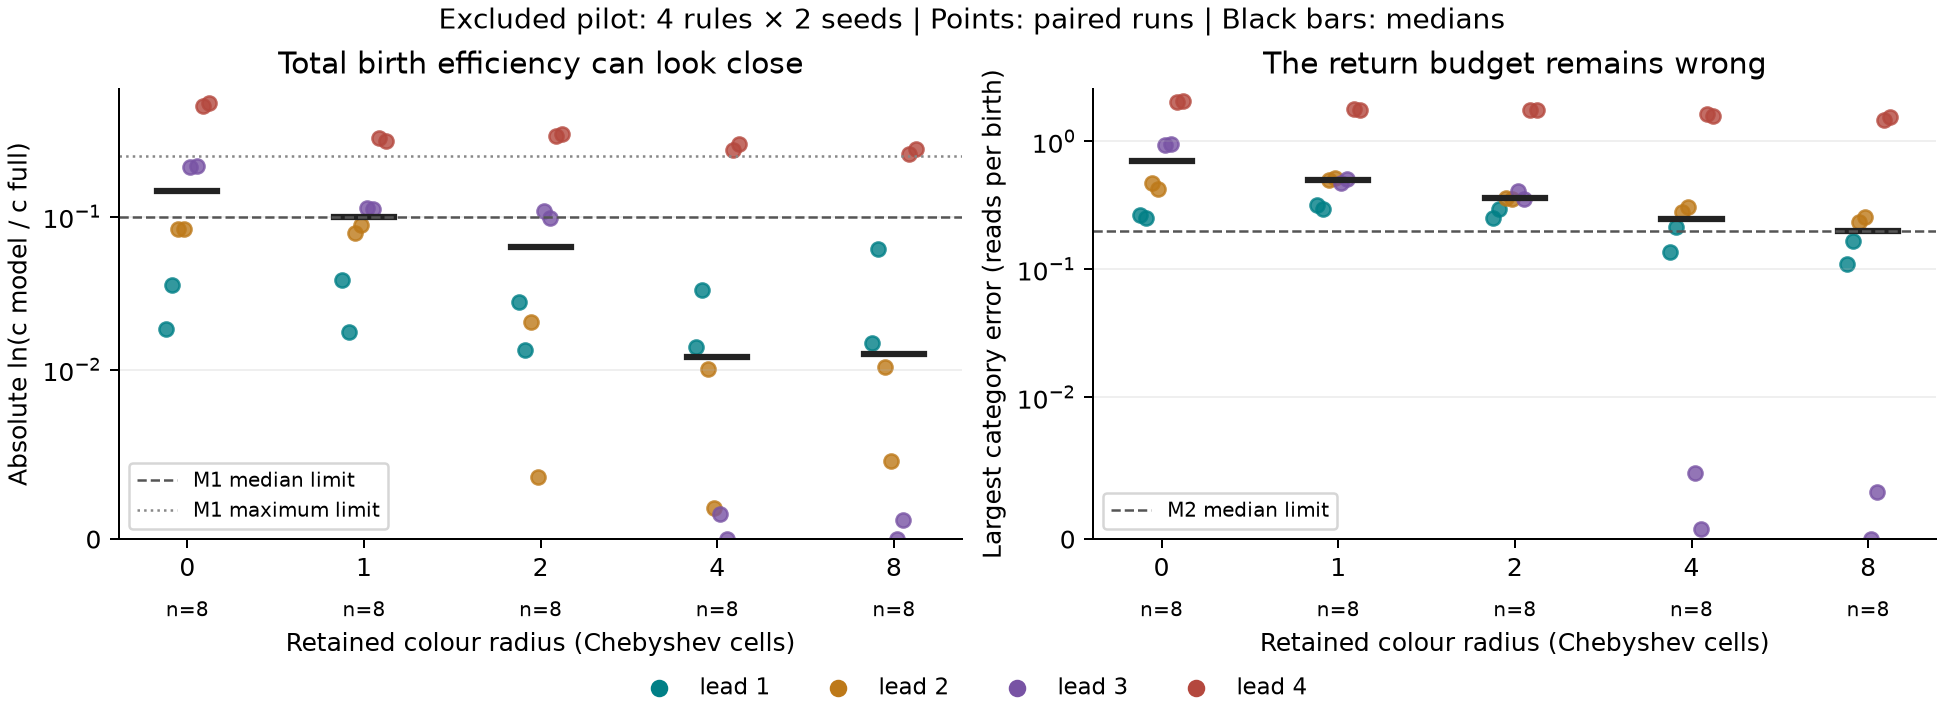

In [4]:
from IPython.display import Image, display
display(Image(filename=str(EXP / 'results/memory_pilot.png')))


## What failed, what we learned, what remains
M1 and M2 fail at both r=4 and r=8; r=8's budget miss is narrow but remains a failure. The lead-4 rule has both paired c estimates roughly 30–35% too high under uniform forgetting. In the lead-2 rule, increased short-loop cost nearly cancels decreased long-return cost, hiding a wrong budget behind a close total. The lead-3 rule has negligible boundary reset exposure and is a weak challenge. Six zero-policy cases never open a measurement window; M3 has only two defined pairs and is uninformative.

Short-loop phase preservation alone with uniform forgotten phases is insufficient here. This is not a general rejection of local mechanisms. Global geometry is retained by the model, the window is early, there are only four pilot rules, and main outcomes remain unopened. The full-ant clock audit is exploratory and not a proof of asymptotic equivalence.

Next proposal: preserve only the old turn bit when scrambling a forgotten phase, then compare preserving two future turns. That distinguishes a directional field from a distant phase clock. It needs a fresh oracle, registration, exposure checks and held-out confirmation; no such result exists yet. The c-law coefficients and later-letter corrections remain unexplained.


In [5]:
# Subsequent read/write-information pilot; original failures stand.
p = EXP / 'results/information_report.json'
subprocess.run(['git', 'ls-files', '--error-unmatch', str(p.relative_to(ROOT))], cwd=ROOT, check=True, capture_output=True)
subprocess.run(['git', '-c', 'core.filemode=false', 'diff', '--exit-code', 'HEAD', '--', str(p.relative_to(ROOT))], cwd=ROOT, check=True, capture_output=True)
print(hashlib.sha256(p.read_bytes()).hexdigest(), p.relative_to(ROOT))
information = json.loads(p.read_text())
print(json.dumps(information['tests'], indent=2))
print('All information candidates fail I2; close total cost does not restore the physical return budget.')


7ad35e2d75c26e58eede00cb6c59e5c530b84e9c39a68c0fe6d7137f5b0804e2 experiments/2026-10-20-c-law-renewal/results/information_report.json
{
  "turn:4": {
    "eligible_pairs": 8,
    "median_abs_log_error": 0.041496427111369166,
    "max_abs_log_error": 0.06270948415997094,
    "cost_has_infinite_error": false,
    "median_max_budget_error": 0.23199599678868682,
    "sensitive_eligible_pairs": 2,
    "sensitive_max_abs_log_error": 0.0420913400014354,
    "sensitive_max_budget_error": 1.0369142481886442,
    "exposed_pairs": 6,
    "exposed_sensitive_pairs": 2,
    "I1": "HELD",
    "I2": "FAILED",
    "I3": "HELD",
    "candidate": "REJECTED_ON_PILOT"
  },
  "next:4": {
    "eligible_pairs": 8,
    "median_abs_log_error": 0.05521801526968151,
    "max_abs_log_error": 0.2463318569364421,
    "cost_has_infinite_error": false,
    "median_max_budget_error": 0.15991916682154758,
    "sensitive_eligible_pairs": 2,
    "sensitive_max_abs_log_error": 0.2463318569364421,
    "sensitive_max_budget_

## Does the boundary birth process differ, or only physical return time?
The next registered audit keeps all earlier failures. A boundary source cannot have been interior on a previous read, since visitation only removes fresh neighbours. Its phase clock therefore counts boundary visits. Compare first/1..4/5..16/>16 native return budgets, the complete empirical inter-birth waiting distribution, and adjacent waiting pairs in fixed bins. Left and right partial waits are retained as censored endpoints.

Same four excluded bases, two seeds, five arms, 2048 warmup plus 8192 measurement reads. No main outcomes, parameter fitting or new treatment. Known synthetic waits calibrate the counters; physical-time stretching must leave native summaries invariant, and reordering equal-marginal waits must change the serial test. The sparse path oracle checks native lags through warmup. Every earlier ant summary must replay exactly.


In [6]:
p = EXP / 'results/native_report.json'
subprocess.run(['git', 'ls-files', '--error-unmatch', str(p.relative_to(ROOT))], cwd=ROOT, check=True, capture_output=True)
subprocess.run(['git', '-c', 'core.filemode=false', 'diff', '--exit-code', 'HEAD', '--', str(p.relative_to(ROOT))], cwd=ROOT, check=True, capture_output=True)
print(hashlib.sha256(p.read_bytes()).hexdigest(), p.relative_to(ROOT))
native = json.loads(p.read_text())
print('Synthetic calibration:', native['calibration'])
for name, digest in native['inputs_sha256'].items():
    q = ROOT / name
    subprocess.run(['git', 'ls-files', '--error-unmatch', name], cwd=ROOT, check=True, capture_output=True)
    assert hashlib.sha256(q.read_bytes()).hexdigest() == digest
    r = json.loads(q.read_text())
    s = r['native']
    assert sum(s['native_lag']) == s['reads'] == r['summary']['boundary_reads']
    assert s['births'] == r['summary']['births']
    assert s['left_partial_reads'] + sum(int(k)*v for k,v in s['wait_counts'].items()) + s['right_censored_reads'] == s['reads']
    assert sum(s['wait_counts'].values()) == s['complete_waits']
    assert sum(s['joint_counts'].values()) == max(0, s['complete_waits']-1)
for mode, result in native['tests'].items():
    print(mode, 'N1', result['N1'], 'N2', result['N2'], 'median native budget error', result['median_budget_error'], 'waiting-pass pairs', result['waiting_pass_pairs'])
    for r in result['sensitive']:
        print('  sensitive seed', r['seed'], 'budget', r['native_budget_error'], 'wait TV', r['wait_tv'], 'serial TV', r['joint_tv'])
print('Full-reference between-seed distances:', native['reference_seed_spreads'])


c5dd3cff437647a2a8eb4fcad5de48f5de56a4f3f7cf30d89cc1134a194121e4 experiments/2026-10-20-c-law-renewal/results/native_report.json
Synthetic calibration: {'seed': 2026102071, 'known_wait_counts_exact': True, 'time_stretch_invariant': True, 'same_marginal_serial_tv': 0.9974937343358395, 'empty_window_accounting': True}


uniform:4 N1 FAILED N2 FAILED median native budget error 0.2289049961356466 waiting-pass pairs 2
  sensitive seed 2026102021 budget 1.1803134344395358 wait TV 0.1288695811670375 serial TV 0.27011696785091494
  sensitive seed 2026102022 budget 1.173555973411283 wait TV 0.14303062507242612 serial TV 0.2937611830188783
turn:4 N1 FAILED N2 FAILED median native budget error 0.22112920981112058 waiting-pass pairs 2
  sensitive seed 2026102021 budget 0.8632407738977129 wait TV 0.15398413802138444 serial TV 0.3168192921342004
  sensitive seed 2026102022 budget 0.8886841166740018 wait TV 0.15883879711704954 serial TV 0.3164849106901025
next:4 N1 FAILED N2 FAILED median native budget error 0.16951628465404817 waiting-pass pairs 2
  sensitive seed 2026102021 budget 1.192697480259164 wait TV 0.12456058726220015 serial TV 0.2646623319989612
  sensitive seed 2026102022 budget 1.1413735921688208 wait TV 0.12387813392451119 serial TV 0.26260145617170755
word2:4 N1 FAILED N2 FAILED median native budget

## Limits of the native-clock comparison
These are descriptive distances between finite early windows, not independent-event significance tests. Complete waits exclude endpoint-censored intervals; the exact endpoint identity checks accounting without assuming their absence. Adjacent-pair agreement would not prove independence or equality of all higher-order history. Two seeds per four previously inspected pilot rules cannot establish general sufficiency. Full-reference seed distances expose sampling variability but do not change registered thresholds. All physical-budget failures remain recorded; main P1–P4 are untested, and the c-law intercept and slope remain unexplained.
